In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import linear_model


In [2]:
#Importing the dataset
df = pd.read_csv(r"C:\Users\kefiw\OneDrive\Desktop\OIBSIPTask1Level2\House_Price_Prediction_Dataset.csv")

In [5]:
#House price prediction dataset
df.head(10)

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056
5,6,3944,1,2,1,1906,Urban,Poor,No,93262
6,7,3671,1,1,2,1948,Rural,Poor,Yes,448722
7,8,3419,2,4,1,1925,Suburban,Good,Yes,594893
8,9,630,2,2,1,1932,Rural,Poor,Yes,652878
9,10,2185,3,3,1,2000,Downtown,Poor,No,340375


In [10]:
#check the data types of the dataframe
print("Data types:")
print(df.dtypes)

Data types:
Id            int64
Area          int64
Bedrooms      int64
Bathrooms     int64
Floors        int64
YearBuilt     int64
Location     object
Condition    object
Garage       object
Price         int64
dtype: object


# Null Check

In [11]:
df.isnull().values.any()

False

In [12]:
if df.isnull().values.any():
    print("Warning: DataFrame contains missing values!")
else:
    print("No missing values.")

No missing values.


# Descriptive statistics

In [14]:
df.describe()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price
count,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000
mean,1000.500000,2786.209500,3.003500,2.55250,1.993500,1961.446000,537676.855000
std,577.494589,1295.146799,1.424606,1.10899,0.809188,35.926695,276428.845719
min,1.000000,501.000000,1.000000,1.00000,1.000000,1900.000000,50005.000000
25%,500.750000,1653.000000,2.000000,2.00000,1.000000,1930.000000,300098.000000
50%,1000.500000,2833.000000,3.000000,3.00000,2.000000,1961.000000,539254.000000
75%,1500.250000,3887.500000,4.000000,4.00000,3.000000,1993.000000,780086.000000
max,2000.000000,4999.000000,5.000000,4.00000,3.000000,2023.000000,999656.000000


# Distribution of the target variable, Price

Text(0.5, 0, 'Price_')

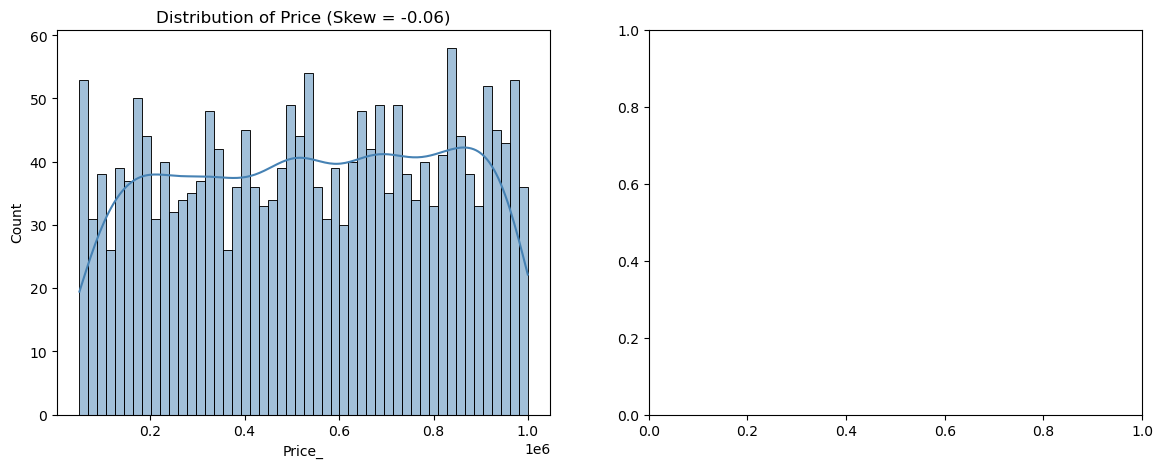

In [19]:
#Histogram and Kernel Density Estimate (KDE)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Raw price
sns.histplot(df['Price'], kde=True, bins=50, ax=axes[0], color='steelblue')
axes[0].set_title(f"Distribution of Price (Skew = {df['Price'].skew():.2f})")
axes[0].set_xlabel("Price_")


# Predictor Features

# One Hot Encoding

In [26]:
#Make a list of all variables needed for training
X = df.loc[:, ["Area", "Bedrooms", "Bathrooms", "Floors", "YearBuilt", "Garage", "Condition", "Price"]]
all_vars = list(X.columns) #The list of features
df_XfeaturesP1 = df.loc[:, all_vars] #storing my list variable to a new data frame

#checking for missing values
print(df_XfeaturesP1.isna().sum())

if df_XfeaturesP1.isnull().values.any():
    print("Warning: DataFrame contains missing values!")
else:
    print("No missing values.")

Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Garage       0
Condition    0
Price        0
dtype: int64
No missing values.


In [28]:
#method
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(categories='auto')
Xd = ohe.fit_transform(df.Location.values.reshape(-1, 1)).toarray()
df_ohe = pd.DataFrame(Xd, columns = ["Location_"+str(int(i)) for i in range(Xd.shape[1])])
#add the encoded feature to the dataframe
df_to_use = pd.concat([df_XfeaturesP1, df_ohe], axis=1)
df_to_use.head()

,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Garage,Condition,Price,Location_0,Location_1,Location_2,Location_3
0,1360,5,4,3,1970,No,Excellent,149919,1.0,0.0,0.0,0.0
1,4272,5,4,3,1958,No,Excellent,424998,1.0,0.0,0.0,0.0
2,3592,2,2,3,1938,No,Good,266746,1.0,0.0,0.0,0.0
3,966,4,2,2,1902,Yes,Fair,244020,0.0,0.0,1.0,0.0
4,4926,1,4,2,1975,Yes,Fair,636056,1.0,0.0,0.0,0.0


# Correlation Heatmap

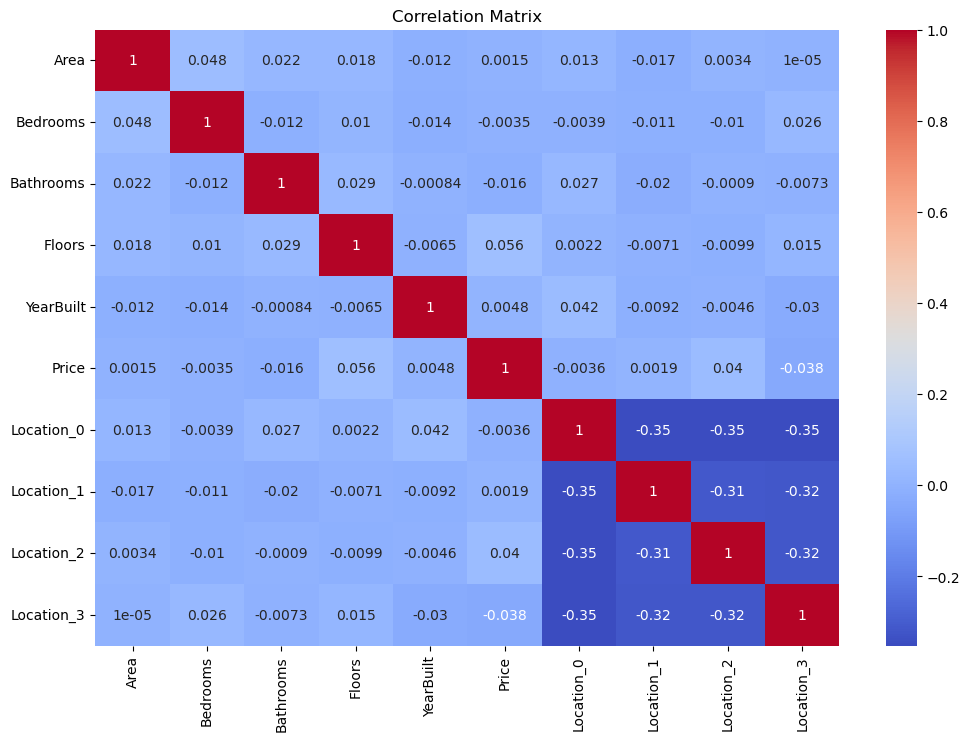

In [32]:
#Relations
plt.figure(figsize=(12,8))
sns.heatmap(df_to_use.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()